# Convolutional Neural Networks

## Project: Write an Algorithm for Landmark Classification


### Introduction

The project folder has the following structure:

* In the main directory you have this notebook, `cnn_from_scratch.ipynb`, that contains the instruction and some questions you will have to answer. Follow this notebook and complete the required sections in order.

* In the `src/` directory you have several source files. As instructed in this notebook, you will open and complete those files, then come back to this notebook to execute some tests that will verify what you have done. While these tests don't guarantee that your work is bug-free, they will help you finding the most obvious problems so you will be able to proceed to the next step with confidence.

* Sometimes you will need to restart the notebook. If you do so, remember to execute also the cells containing the code you have already completed starting from the top, before you move on.

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> Once you have completed all the code implementations, you need to finalize your work by exporting the Jupyter Notebook as an HTML document. Before exporting the notebook to HTML, all the code cells need to have been run so that reviewers can see the final implementation and output. You can then export the notebook by using the menu above and navigating to **File -> Download as -> HTML (.html)**. If you are using Jupyter Lab, you can use **File -> Export Notebook as -> Export Notebook to HTML**. Include the finished document along with this notebook as your submission.

In addition to implementing code, there will be questions that you must answer which relate to the project and your implementation. Each section where you will answer a question is preceded by a **'Question'** header. Carefully read each question and provide thorough answers in the following text boxes that begin with **'Answer:'**. Your project submission will be evaluated based on your answers to each of the questions and the implementation you provide.

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> Code and Markdown cells can be executed using the **Shift + Enter** keyboard shortcut.  Markdown cells can be edited by double-clicking the cell to enter edit mode.

The rubric contains _optional_ "Stand Out Suggestions" for enhancing the project beyond the minimum requirements. If you decide to pursue the "Stand Out Suggestions", you should include the code in this Jupyter notebook.

### Designing and training a CNN from scratch

In this notebook, you will create a CNN that classifies landmarks.  You must create your CNN _from scratch_ (so, you can't use transfer learning _yet_!), and you must attain a test accuracy of at least 50%.

Although 50% may seem low at first glance, it seems more reasonable after realizing how difficult of a problem this is. Many times, an image that is taken at a landmark captures a fairly mundane image of an animal or plant, like in the following picture.

<img src="static_images/train/00.Haleakala_National_Park/084c2aa50d0a9249.jpg" alt="Bird in Haleakalā National Park" style="width: 400px;"/>

Just by looking at that image alone, would you have been able to guess that it was taken at the Haleakalā National Park in Hawaii?

An accuracy of 50% is significantly better than random guessing, which would provide an accuracy of just 2% (100% / 50 classes). In Step 2 of this notebook, you will have the opportunity to greatly improve accuracy by using transfer learning to create a CNN.

Experiment with different architectures, hyperparameters, training strategies, and trust your intuition.  And, of course, have fun!

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 0: Setting up

The following cells make sure that your environment is setup correctly, download the data if you don't have it already, and also check that your GPU is available and ready to go. You have to execute them every time you restart your notebook.

In [1]:
# Requirements are already installed in the project virtual environment.
# Uncomment the line below only if you need to (re)install them.
# %pip install -q -r requirements.txt


In [2]:
from src.helpers import setup_env

# If running locally, this will download dataset (make sure you have at 
# least 2 Gb of space on your hard drive)
setup_env()

GPU available
Dataset already downloaded. If you need to re-download, please delete the directory landmark_images
Reusing cached mean and std


---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 1: Data

In this and the following steps we are going to complete some code, and then execute some tests to make sure the code works as intended. 

Open the file `src/data.py`. It contains a function called `get_data_loaders`. Read the function and complete all the parts marked by `YOUR CODE HERE`. Once you have finished, test that your implementation is correct by executing the following cell (see below for what to do if a test fails):

In [3]:
!.\venv\Scripts\python.exe -m pytest -vv src/data.py -k data_loaders

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 4 items / 1 deselected / 3 selected

src/data.py::test_data_loaders_keys PASSED                               [ 33%]
src/data.py::test_data_loaders_output_type PASSED                        [ 66%]
src/data.py::test_data_loaders_output_shape PASSED                       [100%]

======================= 3 passed, 1 deselected in 4.52s =======================


You should see something like:
```
src/data.py::test_data_loaders_keys PASSED                               [ 33%]
src/data.py::test_data_loaders_output_type PASSED                        [ 66%]
src/data.py::test_data_loaders_output_shape PASSED                       [100%]

======================= 3 passed, 1 deselected in 1.81s ========================
```
If all the tests are `PASSED`, you can move to the next section.

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> **What to do if tests fail**
When a test fails, `pytest` will mark it as `FAILED` as opposed to `PASSED`, and will print a lot of useful output, including a message that should tell you what the problem is. For example, this is the output of a failed test:
> ```
>    def test_data_loaders_keys(data_loaders):
>    
>       assert set(data_loaders.keys()) == {"train", "valid", "test"}
E       AssertionError: assert {'tes', 'train', 'valid'} == {'test', 'train', 'valid'}
E         Extra items in the left set:
E         'tes'
E         Full diff:
E         - {'test', 'train', 'valid'}
E         + {'tes', 'train', 'valid'}
E         ?                          +++++++
>
> src/data.py:171: AssertionError
-------------- Captured stdout setup ----------------------------------------------
Reusing cached mean and std for landmark_images
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2699, 0.2706, 0.3018])
=========== short test summary info ===============================================
FAILED src/data.py::test_data_loaders_keys - AssertionError: The keys of the data_loaders dictionary should be train, valid and test
> ``` 
> In the `short test summary info` you can see a short description of the problem. In this case, the dictionary we are returning has the wrong keys. Going above a little, you can see that the test expects `{'test', 'train', 'valid'}` while we are returning `{'tes', 'train', 'valid'}` (there is a missing `t`). So we can go back to our function, fix that problem and test again.
> 
> In other cases, you might get an error like:
> ```
    def _conv_forward(self, input: Tensor, weight: Tensor, bias: Optional[Tensor]):
        if self.padding_mode != 'zeros':
            return F.conv2d(F.pad(input, self._reversed_padding_repeated_twice, mode=self.padding_mode),
                            weight, bias, self.stride,
                            _pair(0), self.dilation, self.groups)
        return F.conv2d(input, weight, bias, self.stride,
>                       self.padding, self.dilation, self.groups)
E       RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same
>
> ../../../../miniconda3/envs/udacity_starter/lib/python3.7/site-packages/torch/nn/modules/conv.py:440: RuntimeError
> ```
> Looking at the stack trace you should be able to understand what it is going on. In this case, we forgot to add a `.cuda()` to some tensor. For example, the model is on the GPU, but the data aren't.

<img src="static_images/icons/noun-question-mark-869751.png" alt="?" style="width:25px"/> **Question:** Describe your chosen procedure for preprocessing the data. 
- How does your code resize the images (by cropping, stretching, etc)?  What size did you pick for the input tensor, and why?
- Did you decide to augment the dataset?  If so, how (through translations, flips, rotations, etc)?  If not, why not?

<img src="static_images/icons/noun-answer-3361020.png" alt=">" style="width:25px"/> **Answer:** Images are first resized so that their shorter side is 256 pixels (preserving the aspect ratio), then cropped to 224×224 — a random crop during training and a center crop at validation/test time. I chose 224×224 because it is the standard input resolution for ImageNet-pretrained networks and it is a good trade-off between visual detail and GPU memory (the training GPU has only 4 GB of VRAM). I did augment the training set, in this order: random horizontal flip, random rotation (±10°), and color jitter (brightness, contrast and saturation ±0.3). These transforms make the model more robust to viewpoint and lighting changes without destroying the identity of a landmark, which helps generalization on a small dataset. Finally, images are converted to tensors and normalized with the per-channel mean and standard deviation computed once over the training set (and cached), so that all inputs have a similar scale.


### Visualize a Batch of Training Data

Go back to `src/data.py` and complete the function `visualize_one_batch` in all places with the `YOUR CODE HERE` marker. After you're done, execute the following cell and make sure the test `src/data.py::test_visualize_one_batch` is `PASSED`:

In [4]:
!.\venv\Scripts\python.exe -m pytest -vv src/data.py -k visualize_one_batch

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 4 items / 3 deselected / 1 selected

src/data.py::test_visualize_one_batch PASSED                             [100%]

============================== warnings summary ===============================
src/data.py::test_visualize_one_batch
src/data.py::test_visualize_one_batch
  C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argume

We can now use the code we just completed to get a batch of images from your train data loader and look at them.

Visualizing the output of your data loader is a great way to ensure that your data loading and preprocessing (including transforms such as rotations, translations, color transforms...) are working as expected.

Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])


Reusing cached mean and std


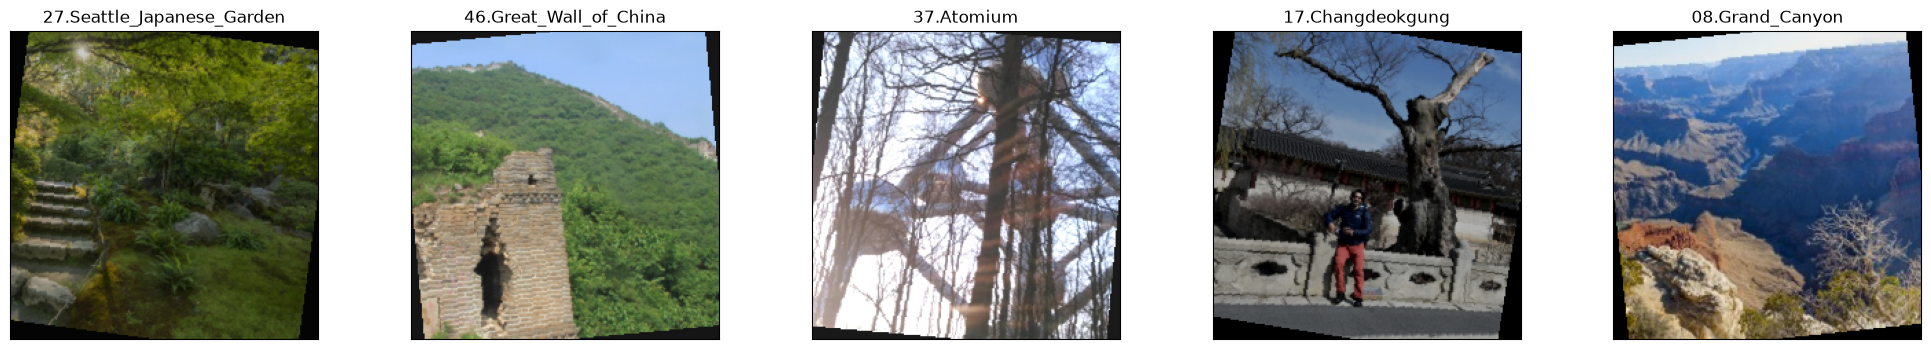

In [5]:
%matplotlib inline
from src.data import visualize_one_batch, get_data_loaders

# use get_data_loaders to get the data_loaders dictionary. Use a batch_size
# of 5, a validation size of 0.01 and num_workers=-1 (all CPUs)
data_loaders = get_data_loaders(batch_size=5, valid_size=0.01, num_workers=0)

visualize_one_batch(data_loaders)


---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 2: Define model

Open `src/model.py` and complete the `MyModel` class filling in all the `YOUR CODE HERE` sections. After you're done, execute the following test and make sure it passes:

In [6]:
!.\venv\Scripts\python.exe -m pytest -vv src/model.py

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 1 item

src/model.py::test_model_construction PASSED                             [100%]

============================== 1 passed in 4.68s ==============================


<img src="static_images/icons/noun-question-mark-869751.png" alt="?" style="width:25px"/> **Question**: Outline the steps you took to get to your final CNN architecture and your reasoning at each step.  

<img src="static_images/icons/noun-answer-3361020.png" alt=">" style="width:25px"/> __Answer:__ I used five convolutional blocks with 32 → 64 → 128 → 256 → 512 filters. Each block is Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2) → Dropout2d, so every block halves the spatial resolution (224 → 112 → 56 → 28 → 14 → 7) while doubling the number of channels. This progressive downsampling lets the network build increasingly abstract features: early layers detect edges and colors, while deeper layers respond to object parts and whole landmarks. BatchNorm keeps activations well scaled and speeds up convergence; Dropout2d (kept small, 0.05, in the convolutional blocks) limits overfitting without slowing down learning, which matters because the dataset only has ~4,000 training images for 50 classes. An AdaptiveAvgPool2d((1, 1)) collapses the final feature map to 512 values, and the classifier head (512 → 512 → 256 → 50, with BatchNorm1d, ReLU and dropout 0.4/0.2) produces the class scores. The last layer has exactly `num_classes` outputs and returns raw logits because `CrossEntropyLoss` applies the softmax internally. Convolutional and linear weights use He/Kaiming initialization so training starts with well-scaled activations.


---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 3: define loss and optimizer

Open `src/optimization.py` and complete the `get_loss` function, then execute the test and make sure it passes:

In [7]:
!.\venv\Scripts\python.exe -m pytest -vv src/optimization.py -k get_loss

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 7 items / 6 deselected / 1 selected

src/optimization.py::test_get_loss PASSED                                [100%]

======================= 1 passed, 6 deselected in 2.17s =======================


Then, in the same file, complete the `get_optimizer` function then execute its tests, and make sure they all pass:

In [8]:
!.\venv\Scripts\python.exe -m pytest -vv src/optimization.py -k get_optimizer

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 7 items / 1 deselected / 6 selected

src/optimization.py::test_get_optimizer_type PASSED                      [ 16%]
src/optimization.py::test_get_optimizer_is_linked_with_model PASSED      [ 33%]
src/optimization.py::test_get_optimizer_returns_adam PASSED              [ 50%]
src/optimization.py::test_get_optimizer_sets_learning_rate PASSED        [ 66%]
src/optimization.py::test_get_optimizer_sets_momentum PASSED             [ 83%]
src/optimization.py::test_get_optimizer_sets_weight_decat PASSED         [100%]

======================= 6 passed, 1 deselected in 3.69s 

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 4: Train and Validate the Model

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> Testing ML code is notoriously difficult. The tests in this section merely exercise the functions you are completing, so it will help you catching glaring problems but it won't guarantee that your training code is bug-free. If you see that your loss is not decreasing, for example, that's a sign of a bug or of a flawed model design. Use your judgement.

Open `src/train.py` and complete the `train_one_epoch` function, then run the tests:

In [9]:
!.\venv\Scripts\python.exe -m pytest -vv src/train.py -k train_one_epoch

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_train_one_epoch PASSED                                [100%]

======================= 1 passed, 3 deselected in 8.64s =======================


Now complete the `valid` function, then run the tests:

In [10]:
!.\venv\Scripts\python.exe -m pytest -vv src/train.py -k valid_one_epoch

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_valid_one_epoch PASSED                                [100%]

======================= 1 passed, 3 deselected in 8.12s =======================


Now complete the `optimize` function, then run the tests:

In [11]:
!.\venv\Scripts\python.exe -m pytest -vv src/train.py -k optimize

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_optimize PASSED                                       [100%]

======================= 1 passed, 3 deselected in 9.91s =======================


Finally, complete the `test` function then run the tests:

In [12]:
!.\venv\Scripts\python.exe -m pytest -vv src/train.py -k one_epoch_test

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_one_epoch_test PASSED                                 [100%]

======================= 1 passed, 3 deselected in 7.90s =======================


---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 5: Putting everything together

Allright, good job getting here! Now it's time to see if all our hard work pays off. In the following cell we will train your model and validate it against the validation set.

Let's start by defining a few hyperparameters. Feel free to experiment with different values and try to optimize your model:

In [13]:
batch_size = 32        # size of the minibatch for stochastic gradient descent (or Adam)
valid_size = 0.15      # fraction of the training data to reserve for validation
num_epochs = 80        # number of epochs for training
num_classes = 50       # number of classes. Do not change this
dropout = 0.4          # dropout for our model
learning_rate = 0.001  # Learning rate for SGD (or Adam)
opt = 'adam'           # optimizer. 'sgd' or 'adam'
weight_decay = 1e-4    # regularization. Increase this to combat overfitting


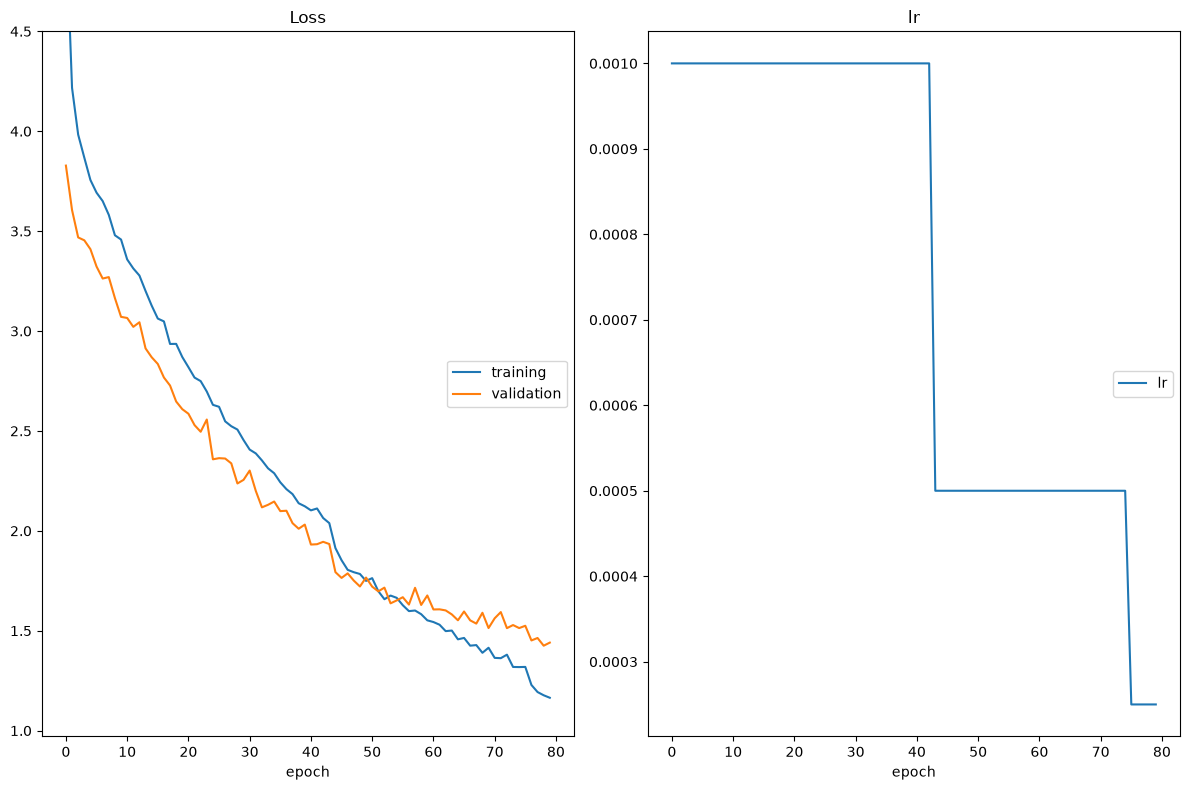

MyModel(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Dropout2d(p=0.05, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Dropout2d(p=0.05, inplace=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=Tr

In [14]:
import numpy as np
import torch

from src.data import get_data_loaders
from src.train import optimize
from src.optimization import get_optimizer, get_loss
from src.model import MyModel

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# get the data loaders using batch_size and valid_size defined in the previous
# cell
# HINT: do NOT copy/paste the values. Use the variables instead
data_loaders = get_data_loaders(
    batch_size=batch_size, valid_size=valid_size, num_workers=0
)

# instance model MyModel with num_classes and drouput defined in the previous
# cell
model = MyModel(num_classes=num_classes, dropout=dropout)

# Get the optimizer using get_optimizer and the model you just created, the learning rate,
# the optimizer and the weight decay specified in the previous cell
optimizer = get_optimizer(
    model,
    optimizer=opt,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
    momentum=0.9,
)

# Get the loss using get_loss
loss = get_loss()

optimize(
    data_loaders,
    model,
    optimizer,
    loss,
    n_epochs=num_epochs,
    save_path="checkpoints/best_val_loss.pt",
    interactive_tracking=True,
    early_stopping_patience=20,
)


---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 6: testing against the Test Set

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> only run this *after* you have completed hyperpameter optimization. Do not optimize hyperparameters by looking at the results on the test set, or you might overfit on the test set (bad, bad, bad)

Run the code cell below to try out your model on the test dataset of landmark images. Ensure that your test accuracy is greater than 50%.

In [15]:
# load the model that got the best validation accuracy
from src.train import one_epoch_test
from src.model import MyModel
import torch

model = MyModel(num_classes=num_classes, dropout=dropout)

# load the weights in 'checkpoints/best_val_loss.pt'
model.load_state_dict(torch.load("checkpoints/best_val_loss.pt", map_location="cpu"))

# Run test
one_epoch_test(data_loaders['test'], model, loss)


Testing:   0%|                                           | 0/40 [00:00<?, ?it/s]

Testing:   2%|▉                                  | 1/40 [00:00<00:12,  3.00it/s]

Testing:   5%|█▊                                 | 2/40 [00:00<00:12,  3.05it/s]

Testing:   8%|██▋                                | 3/40 [00:00<00:12,  3.03it/s]

Testing:  10%|███▌                               | 4/40 [00:01<00:12,  2.98it/s]

Testing:  12%|████▍                              | 5/40 [00:01<00:11,  2.96it/s]

... (34 outputs left out)

Testing: 100%|██████████████████████████████████| 40/40 [00:14<00:00,  2.52it/s]

Testing: 100%|██████████████████████████████████| 40/40 [00:14<00:00,  2.82it/s]

Test Loss: 1.272922


Test Accuracy: 66% (825/1250)


1.2729221530258654

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 7: Export using torchscript

Great job creating your CNN models! Now that you have put in all the hard work of creating accurate classifiers, let's export it so we can use it in our app.

But first, as usual, we need to complete some code!

Open `src/predictor.py` and fill up the missing code, then run the tests:

In [16]:
!.\venv\Scripts\python.exe -m pytest -vv src/predictor.py

============================= test session starts =============================
platform win32 -- Python 3.14.7, pytest-9.2.0, pluggy-1.7.0 -- C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging
plugins: platformdirs-4.14.5
collecting ... collected 1 item

src/predictor.py::test_model_construction PASSED                         [100%]

============================== 1 passed in 6.70s ==============================


Allright, now we are ready to export our model using our Predictor class:

In [17]:
# NOTE: you might need to restart the notebook before running this step
# If you get an error about RuntimeError: Can't redefine method: forward on class
# restart your notebook then execute only this cell
from src.predictor import Predictor
from src.helpers import compute_mean_and_std
from src.model import MyModel
from src.data import get_data_loaders
import torch

data_loaders = get_data_loaders(batch_size=1, num_workers=0)

# First let's get the class names from our data loaders
class_names = data_loaders["train"].dataset.classes

# Then let's move the model_transfer to the CPU
# (we don't need GPU for inference)
model = MyModel(num_classes=50, dropout=0.5).cpu()

# Let's make sure we use the right weights by loading the
# best weights we have found during training
# NOTE: remember to use map_location='cpu' so the weights
# are loaded on the CPU (and not the GPU)
model.load_state_dict(torch.load("checkpoints/best_val_loss.pt", map_location="cpu"))

# Let's wrap our model using the predictor class
mean, std = compute_mean_and_std()
predictor = Predictor(model, class_names, mean, std).cpu()

# Export using torch.jit.script
scripted_predictor = torch.jit.script(predictor)

scripted_predictor.save("checkpoints/original_exported.pt")


Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])
Reusing cached mean and std


C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Now let's make sure the exported model has the same performance as the original one, by reloading it and testing it. The Predictor class takes different inputs than the non-wrapped model, so we have to use a specific test loop:

In [18]:
import torch

# Load using torch.jit.load
model_reloaded = torch.jit.load("checkpoints/original_exported.pt")


C:\udacity\Deep-Learning\Udacity_Deep_Learning_P2_Landmark_Classification_and_Tagging\venv\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


In [19]:
from src.predictor import predictor_test

pred, truth = predictor_test(data_loaders['test'], model_reloaded)

  0%|                                                  | 0/1250 [00:00<?, ?it/s]

  0%|                                          | 1/1250 [00:00<02:52,  7.25it/s]

  0%|▏                                         | 5/1250 [00:00<00:53, 23.37it/s]

  1%|▍                                        | 13/1250 [00:00<00:27, 44.56it/s]

  2%|▋                                        | 21/1250 [00:00<00:22, 55.09it/s]

  2%|▉                                        | 29/1250 [00:00<00:19, 61.87it/s]

... (142 outputs left out)

 99%|██████████████████████████████████████▋| 1241/1250 [00:16<00:00, 78.35it/s]

100%|██████████████████████████████████████▉| 1249/1250 [00:16<00:00, 78.63it/s]

100%|███████████████████████████████████████| 1250/1250 [00:16<00:00, 76.80it/s]

Accuracy: 0.6576


Finally, let's have a look at the confusion matrix of the model we are going to use in production:

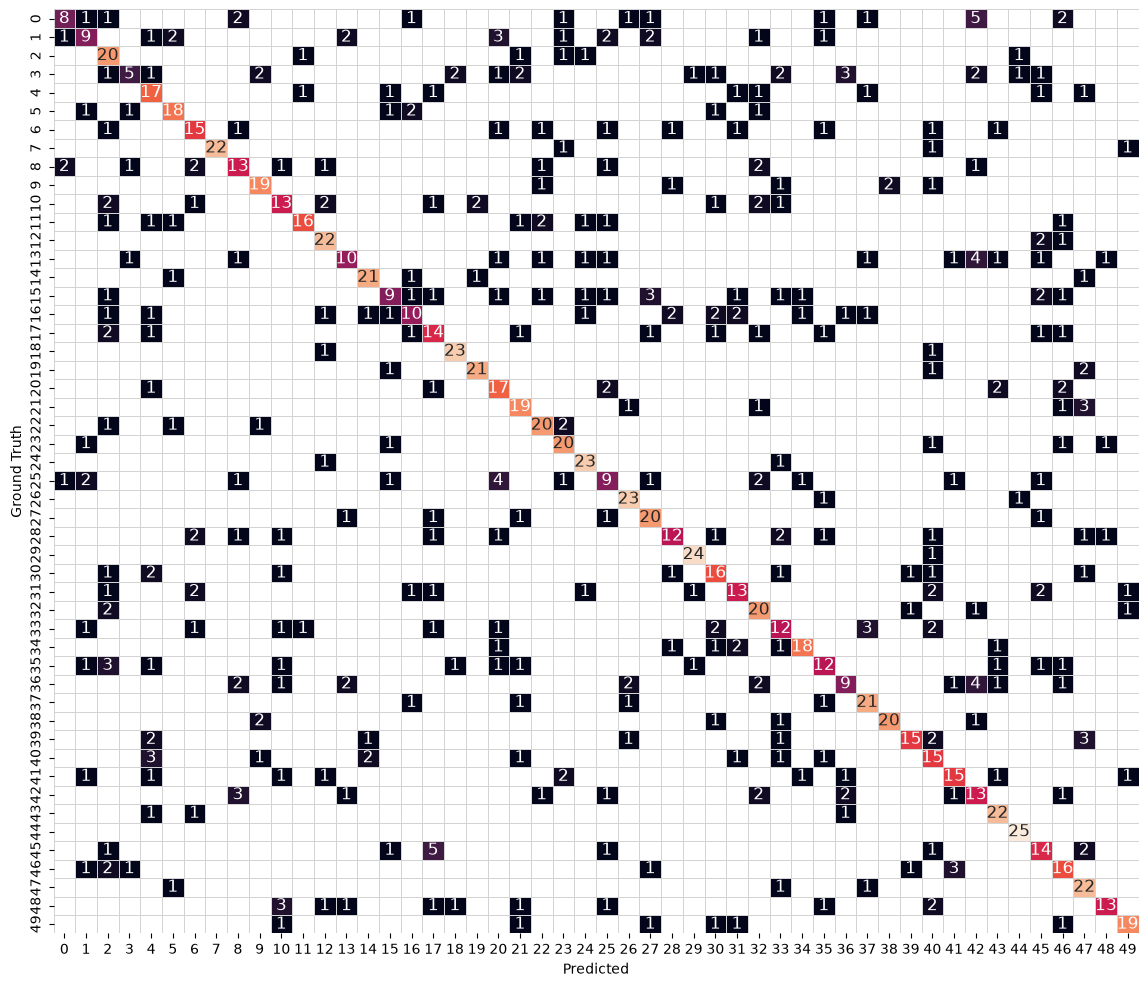

In [20]:
from src.helpers import plot_confusion_matrix

plot_confusion_matrix(pred, truth)